In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Read image in grayscale
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
rows, cols = img.shape

In [3]:
sp = img.copy()

for i in range(rows):
    for j in range(cols):
        r = np.random.rand()

        if r < 0.02:
            sp[i, j] = 0
        elif r > 0.98:
            sp[i, j] = 255

In [4]:
# 2. Add Gaussian Noise
noise = np.random.normal(0, 20, (rows, cols))
gaussian = np.clip(img + noise, 0, 255).astype(np.uint8)

In [5]:
# 3. Remove Salt and Pepper Noise using Median Filter
median = sp.copy()

for i in range(1, rows-1):
    for j in range(1, cols-1):
        window = sp[i-1:i+2, j-1:j+2]
        median[i, j] = np.median(window)

In [6]:
# 4. Remove Gaussian Noise using Manual Gaussian Blur
blur = np.zeros((rows, cols), dtype=np.uint8)

kernel = np.array([[1, 2, 1],
                   [2, 4, 2],
                   [1, 2, 1]]) / 16

for i in range(1, rows-1):
    for j in range(1, cols-1):
        window = gaussian[i-1:i+2, j-1:j+2]
        value = np.sum(window * kernel)
        blur[i, j] = int(value)

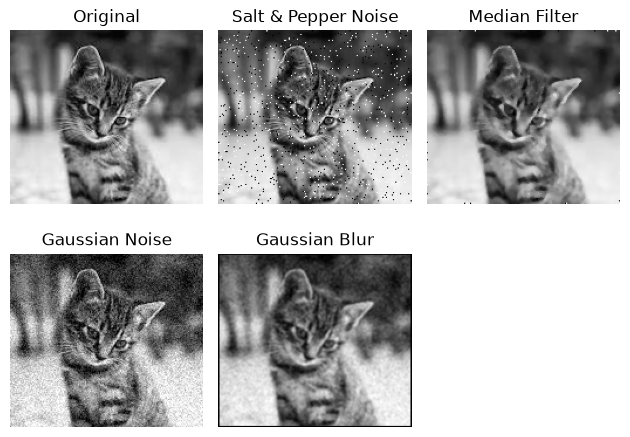

In [7]:
# 5. Display Results
images = [img, sp, median, gaussian, blur]

titles = ['Original', 'Salt & Pepper Noise',
          'Median Filter', 'Gaussian Noise',
          'Gaussian Blur']

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()